# 402 – Datasets for Quantum Machine Learning

Before a quantum classifier (QSVM, VQC, …) can learn anything it needs **data**. This notebook is a tour of the toy datasets used by the quantum machine learning (QML) notebooks in this folder, and of how classical data is prepared so that it fits on a small number of qubits.

**What you will learn**
1. Why QML datasets are reduced to just a few features.
2. The three-step preparation recipe: standardise → PCA → scale to $[-1, 1]$.
3. The **ad hoc** dataset, which was designed specifically for quantum classifiers.
4. Five classical datasets (breast cancer, digits, Gaussian, iris, wine) and how they look after preparation.

**No quantum backend is needed here.** Everything in this notebook is classical data preparation; the data is fed to quantum circuits in the classifier notebooks.

**Where this comes from.** Qiskit Aqua shipped these datasets as `qiskit.ml.datasets`. Aqua was removed; only `ad_hoc_data` survived (now in `qiskit_machine_learning.datasets`). The shared module `qml_datasets.py` in this folder rebuilds the others with scikit-learn, keeping the same interface.

**Related notebooks**
- `412-Variational Quantum Classifier.ipynb`, `415-QSVM.ipynb`, `415-QSVM-Multiclass.ipynb` – classifiers trained on these datasets.
- `701-AQUA-ML.ipynb` – uses the same `qml_datasets` module.

## Why only a few features?

A quantum classifier first loads each data point $\vec{x}$ into a quantum state using a **feature map**, a circuit whose rotation angles depend on the features: $\vec{x} \mapsto |\phi(\vec{x})\rangle$. Typical feature maps (e.g. `ZZFeatureMap`) use **one qubit per feature**. Simulators and today's hardware only handle a handful of qubits, so we reduce each dataset to $n = 2$ or $3$ features.

The preparation recipe in `qml_datasets.py` is:

1. **Standardise** – shift and scale every feature to mean 0 and variance 1, so that no feature dominates just because of its units.
2. **PCA (principal component analysis)** – rotate the data and keep only the $n$ directions with the most variance. This compresses e.g. 30 features into 2 while keeping as much information as possible.
3. **Scale to $[-1, 1]$** – the features become rotation angles in the feature map, so they must lie in a fixed, small range.

Finally `training_size` samples **per class** go into the training set and `test_size` samples per class into the test set.

## Step 1 – Imports and settings

- `qdatasets` holds one function per dataset; `describe_dataset` prints a short summary.
- Every dataset function returns the same 4-tuple:

| Element | Meaning |
|---|---|
| `sample_train` | all training samples as an array of shape `(samples, n)` |
| `training_input` | dictionary `{class label: training samples of that class}` |
| `test_input` | dictionary `{class label: test samples of that class}` |
| `class_labels` | list of class names, e.g. `['A', 'B']` |

- `training_size` and `test_size` are numbers of samples **per class**; `n` is the number of features (= qubits).

In [1]:
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qml_datasets import qdatasets, describe_dataset

training_size = 10   # training samples per class
test_size = 4        # test samples per class
n = 2                # features per sample (= qubits in the feature map)

## Step 2 – The ad hoc dataset

The ad hoc dataset comes from Havlíček *et al.*, "Supervised learning with quantum-enhanced feature spaces", *Nature* **567**, 209 (2019). It was constructed so that the two classes are **perfectly separable by a quantum feature map** (the `ZZFeatureMap`), while being hard for simple classical methods. It is the standard "hello world" for quantum kernels.

- `n` is 2 or 3 (number of features/qubits).
- `gap` is a margin left empty between the two classes; it must be below 1. A larger gap makes the problem easier.
- With `plot_data=True` Qiskit draws the whole feature space: the background colours show which class each region belongs to, and the markers are the drawn samples.

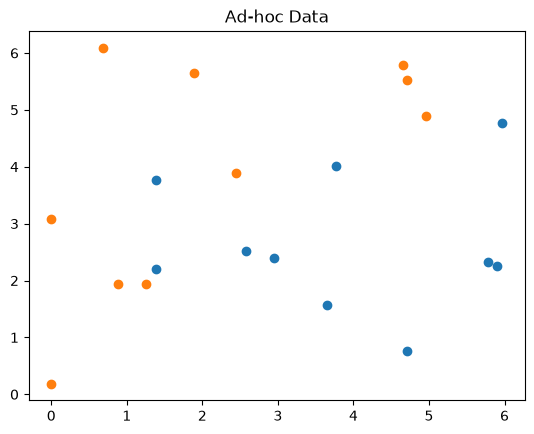

class labels : ['A', 'B']
sample_train : 20 samples x 2 features
  class 'A'  :  10 training,   4 test samples
  class 'B'  :  10 training,   4 test samples


In [2]:
data = qdatasets.ad_hoc_data(training_size, test_size, n, gap=0.3, plot_data=True)
describe_dataset(data)

Let's unpack the tuple and look inside. Each test sample is a point $(x_1, x_2)$ with both coordinates in $[0, 2\pi]$ – they are used directly as rotation angles. (In Aqua this dataset could also be resampled with `sample_ad_hoc_data`; that function was removed, because `ad_hoc_data` now draws training and test samples in one call.)

In [3]:
sample_train, training_input, test_input, class_labels = data
for label in class_labels:
    print(f'Test samples of class {label}:')
    print(test_input[label].round(3))

Test samples of class A:
[[0.565 5.592]
 [2.639 2.45 ]
 [5.027 3.456]
 [0.88  3.204]]
Test samples of class B:
[[4.084 2.388]
 [0.126 0.503]
 [0.251 5.781]
 [1.948 0.565]]


## Step 3 – Breast cancer dataset

The Wisconsin breast cancer dataset: **569** tumour samples, **30** measured features (radius, texture, …), **2** classes – malignant (`A`) and benign (`B`). PCA squeezes the 30 features into 2. The plot shows the training samples after preparation; notice that the two classes already separate fairly well in just two dimensions.

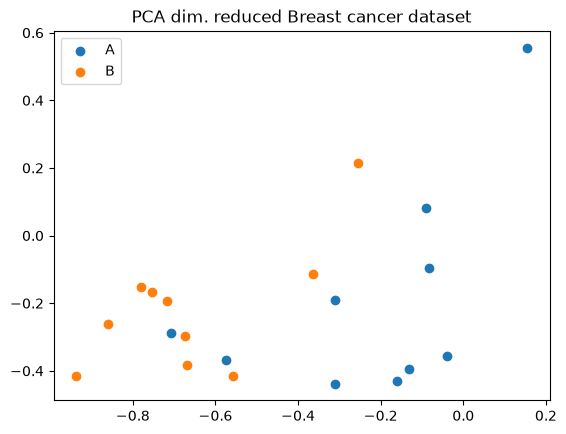

class labels : ['A', 'B']
sample_train : 398 samples x 2 features
  class 'A'  :  10 training,   4 test samples
  class 'B'  :  10 training,   4 test samples


In [4]:
data = qdatasets.breast_cancer(training_size, test_size, n, plot_data=True)
describe_dataset(data)

## Step 4 – Digits dataset

Handwritten digits: **1797** images of $8\times8$ pixels (**64** features), **10** classes (`'0'` … `'9'`). Compressing 64 features into 2 loses a lot of information, so the classes overlap heavily – a 10-class problem in 2 dimensions is hard for *any* classifier.

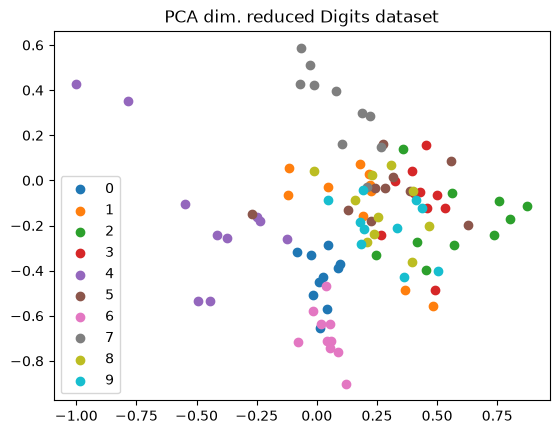

class labels : ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
sample_train : 1257 samples x 2 features
  class '0'  :  10 training,   4 test samples
  class '1'  :  10 training,   4 test samples
  class '2'  :  10 training,   4 test samples
  class '3'  :  10 training,   4 test samples
  class '4'  :  10 training,   4 test samples
  class '5'  :  10 training,   4 test samples
  class '6'  :  10 training,   4 test samples
  class '7'  :  10 training,   4 test samples
  class '8'  :  10 training,   4 test samples
  class '9'  :  10 training,   4 test samples


In [5]:
data = qdatasets.digits(training_size, test_size, n, plot_data=True)
describe_dataset(data)

## Step 5 – Gaussian dataset

A synthetic dataset: two clouds of points drawn from normal (Gaussian) distributions centred at $-0.5$ and $+0.5$ in every dimension. It is a simple sanity check – almost any classifier should separate it. The `seed` argument (default 7) makes it reproducible.

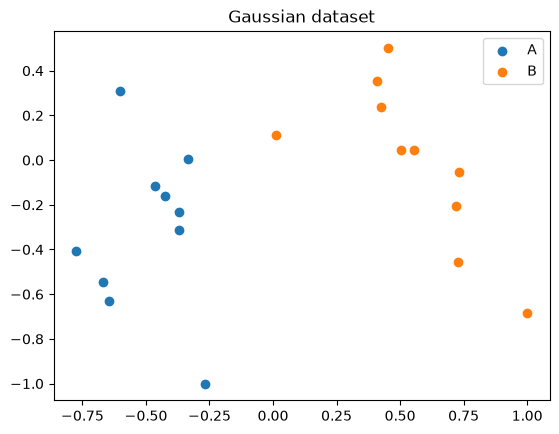

class labels : ['A', 'B']
sample_train : 28 samples x 2 features
  class 'A'  :  10 training,   4 test samples
  class 'B'  :  10 training,   4 test samples


In [6]:
data = qdatasets.gaussian(training_size, test_size, n, plot_data=True)
describe_dataset(data)

## Step 6 – Iris dataset

The classic iris flower dataset: **150** flowers, **4** features (sepal and petal length and width), **3** species – classes `A`, `B`, `C`. One species separates cleanly from the other two, which partly overlap.

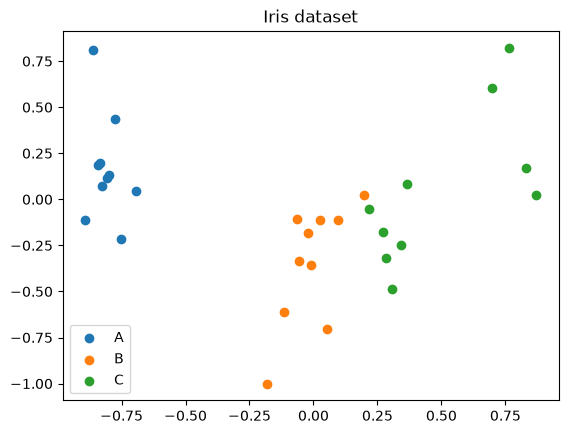

class labels : ['A', 'B', 'C']
sample_train : 105 samples x 2 features
  class 'A'  :  10 training,   4 test samples
  class 'B'  :  10 training,   4 test samples
  class 'C'  :  10 training,   4 test samples


In [7]:
data = qdatasets.iris(training_size, test_size, n, plot_data=True)
describe_dataset(data)

## Step 7 – Wine dataset

**178** wines from three cultivars (grape varieties), **13** chemical features (alcohol, acidity, …), **3** classes. This dataset keeps only 10 % of the samples for testing, so a class can end up with fewer than `test_size` test samples (class `A` gets only 3 below).

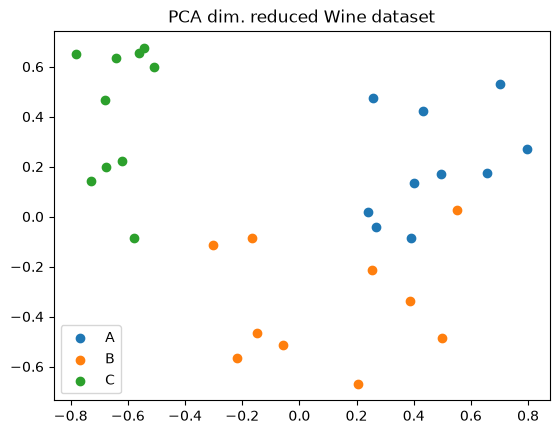

class labels : ['A', 'B', 'C']
sample_train : 160 samples x 2 features
  class 'A'  :  10 training,   3 test samples
  class 'B'  :  10 training,   4 test samples
  class 'C'  :  10 training,   4 test samples


In [8]:
data = qdatasets.wine(training_size, test_size, n, plot_data=True)
describe_dataset(data)

## Summary

- Quantum classifiers use roughly one qubit per feature, so classical datasets are reduced to a few features with **standardise → PCA → scale to $[-1, 1]$**.
- The **ad hoc** dataset is built to suit a quantum feature map; the classical datasets show how real-world data looks after compression.
- All datasets share one interface, so a classifier notebook can switch datasets by changing a single line.

## Exercises

1. Set `n = 3` and rerun. What changes in `describe_dataset`? (The plots still show only the first two features.)
2. Raise `gap` in the ad hoc dataset to 0.6. How does the plot change?
3. Which dataset looks easiest to classify after reduction, and which hardest? Why does the digits dataset look so mixed?
4. Open `qml_datasets.py` and find the three preparation steps in `_prepare`. What would go wrong if we skipped the scaling to $[-1, 1]$?